# Taxi-v3: From-Scratch Tabular Q-learning

Run **Kernel → Restart & Run All** after installing `requirements.txt`. This notebook is initially **unexecuted**; fill the report using your own generated metrics. The Python scripts in the same folder are imported below.

## 1. Imports and reproducibility
The algorithm is implemented in `agent.py` and the training loop in `main.py`, without external RL algorithm packages.

In [11]:
from pathlib import Path
import gymnasium as gym
import numpy as np
from IPython.display import display, Image
from main import train_agent
from utils import plot_training_curves, evaluate_policy, save_agent_gif
from experiments import run_experiments

SEED = 42
OUTPUT = Path("outputs/notebook")
OUTPUT.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
print("Gymnasium version:", gym.__version__)

Gymnasium version: 1.2.3


## 2. Explore Taxi-v3
Taxi-v3 uses 500 states and six actions (south, north, east, west, pickup, drop-off). Default rewards are −1 per regular step, −10 for illegal pickup/drop-off, and +20 for a successful drop-off. The standard time limit is 200 steps. These values come from the environment specification; the sample step below merely inspects the API.

In [12]:
env = gym.make("Taxi-v3")
state, info = env.reset(seed=SEED)
print("Observation space:", env.observation_space)
print("Number of states:", env.observation_space.n)
print("Action space:", env.action_space)
print("Number of actions:", env.action_space.n)
print("Example initial state:", state)
print("Example action mask:", info.get("action_mask"))
next_state, reward, terminated, truncated, step_info = env.step(0)
print("One transition:", next_state, reward, terminated, truncated)
env.close()

Observation space: Discrete(500)
Number of states: 500
Action space: Discrete(6)
Number of actions: 6
Example initial state: 386
Example action mask: [1 1 0 1 0 0]
One transition: 486 -1 False False


## 3. Train the Q-learning agent
Exploration decays once per episode. Terminal transitions have no bootstrapped value. The final Q-table and histories are saved for submission and inspection.

In [13]:
CONFIG = dict(
    episodes=15_000, alpha=0.1, gamma=0.95,
    epsilon_start=1.0, epsilon_min=0.01,
    epsilon_decay=0.9995, seed=SEED,
)
agent, history = train_agent(**CONFIG)
agent.save(OUTPUT / "q_table.npy")
np.savez(OUTPUT / "training_history.npz", **history)
print("Q-table shape:", agent.q_table.shape)
print("Final epsilon:", agent.epsilon)

Q-table shape: (500, 6)
Final epsilon: 0.01


## 4. Learning curves
Raw reward/steps/epsilon curves are overlaid with rolling means and saved as PNG. Look for reward improvements and shorter journeys; do not infer convergence from one spike.

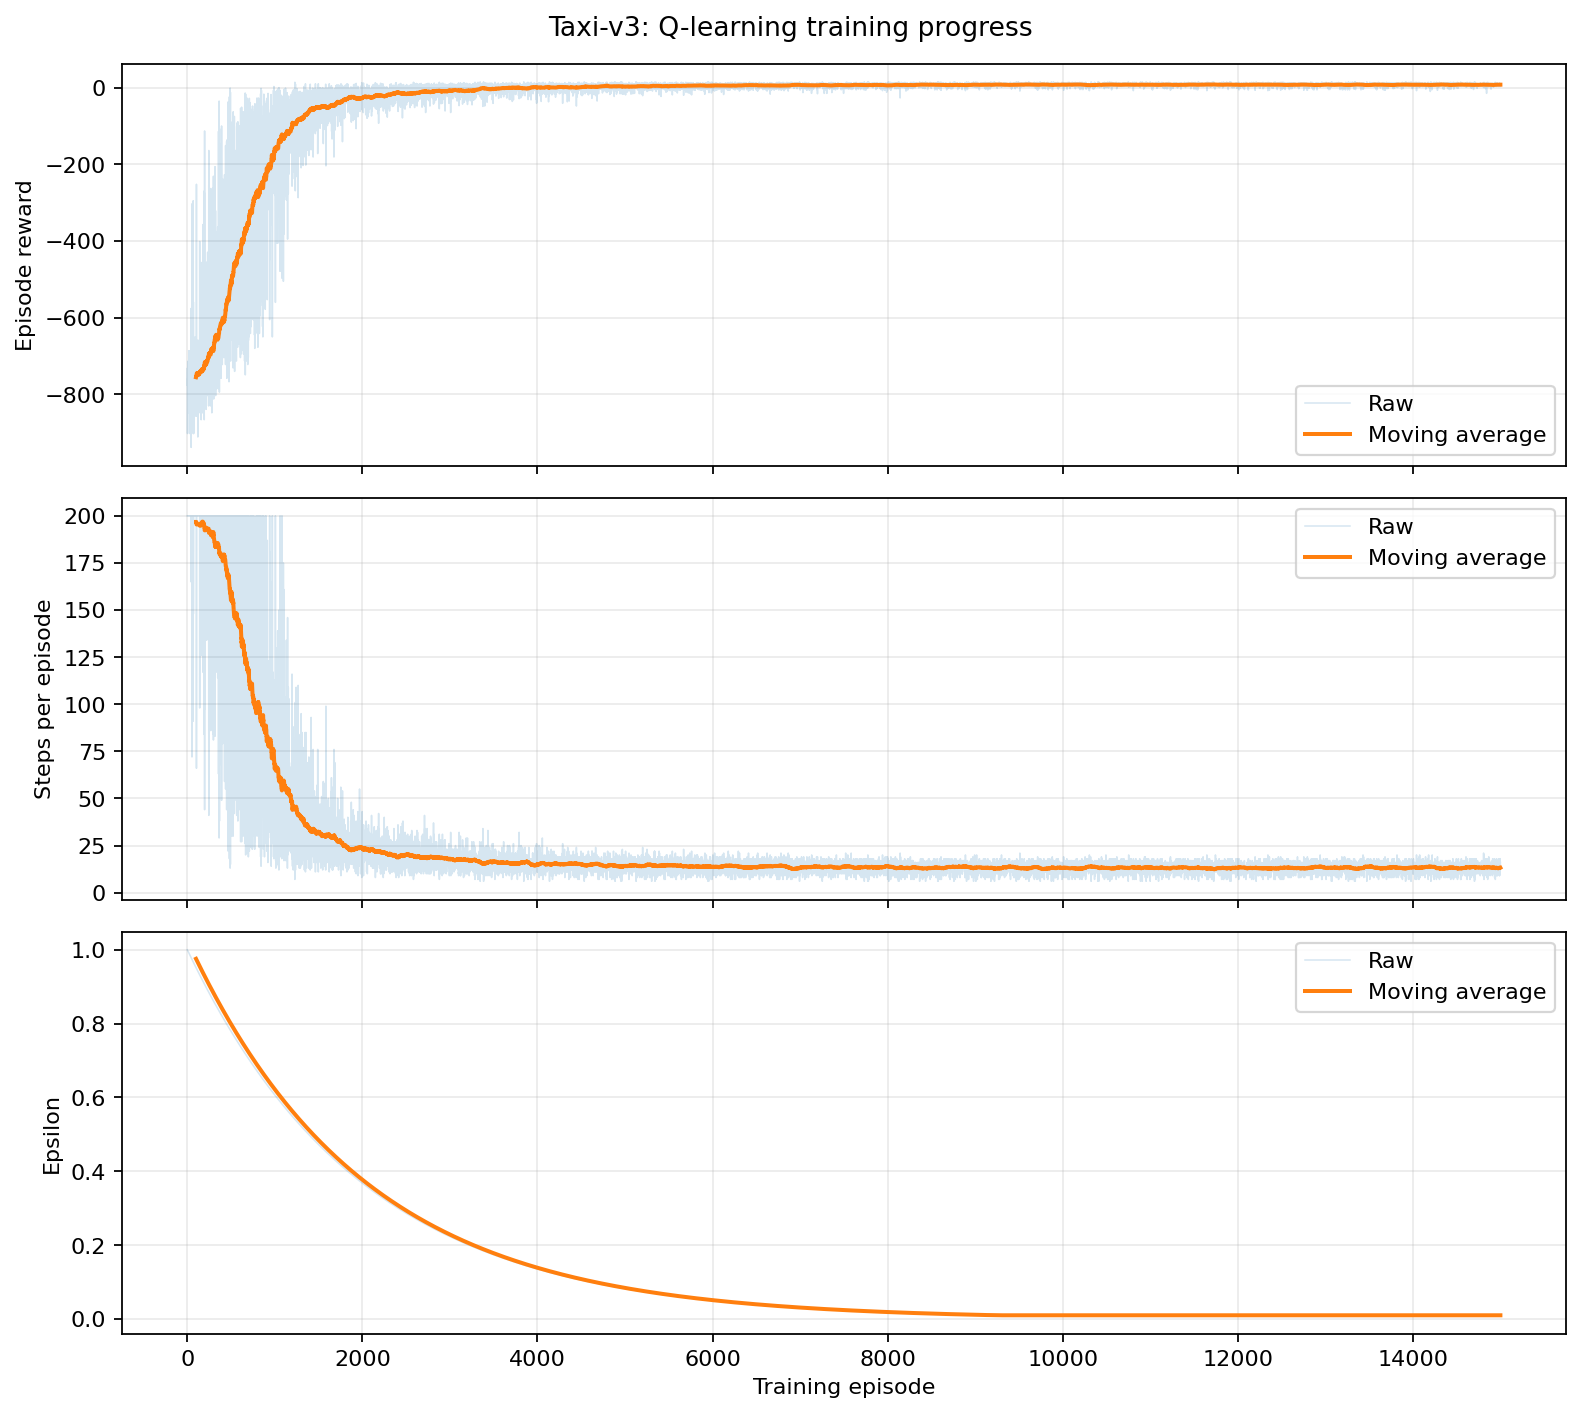

In [14]:
curve_path = plot_training_curves(**history, output_dir=OUTPUT, window=100)
display(Image(filename=str(curve_path)))

## 5. Greedy policy evaluation
Evaluation disables exploration and does **not** update the Q-table. Success is a legal delivery (+20 on a terminated episode).

In [15]:
metrics = evaluate_policy(agent, episodes=100, seed=SEED + 10_000)
print(f"Mean evaluation reward: {metrics['mean_reward']:.2f}")
print(f"Success rate: {metrics['success_rate']:.1%}")
print(f"Average steps: {metrics['average_steps']:.2f}")

Mean evaluation reward: 8.05
Success rate: 100.0%
Average steps: 12.95


## 6. Render a successful agent rollout
The helper retries different initial states but only saves the GIF when the greedy agent actually completes a delivery. If no successful rollout occurs, train longer or adjust the exploration schedule.

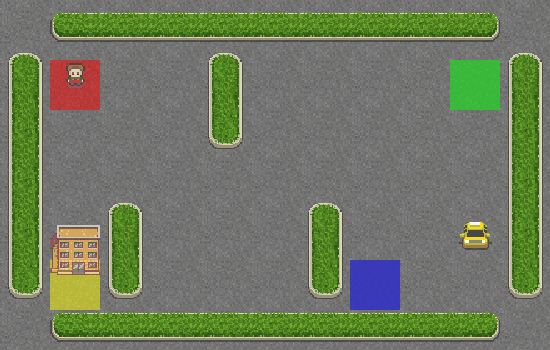

In [16]:
gif_path = save_agent_gif(agent, OUTPUT / "taxi_agent.gif", seed=SEED + 20_000)
display(Image(filename=str(gif_path)))

## 7. Hyperparameter sensitivity
Nine one-factor-at-a-time settings × three training seeds. Each chart shows the mean smoothed reward ± one standard deviation; the two CSV files include individual runs and grouped summary metrics. This cell may take longer than the main training cell.

Training alpha=0.05, seed=0 ...
Training alpha=0.05, seed=1 ...
Training alpha=0.05, seed=2 ...
Training alpha=0.1, seed=0 ...
Training alpha=0.1, seed=1 ...
Training alpha=0.1, seed=2 ...
Training alpha=0.5, seed=0 ...
Training alpha=0.5, seed=1 ...
Training alpha=0.5, seed=2 ...
Training gamma=0.9, seed=0 ...
Training gamma=0.9, seed=1 ...
Training gamma=0.9, seed=2 ...
Training gamma=0.95, seed=0 ...
Training gamma=0.95, seed=1 ...
Training gamma=0.95, seed=2 ...
Training gamma=0.99, seed=0 ...
Training gamma=0.99, seed=1 ...
Training gamma=0.99, seed=2 ...
Training epsilon_decay=0.999, seed=0 ...
Training epsilon_decay=0.999, seed=1 ...
Training epsilon_decay=0.999, seed=2 ...
Training epsilon_decay=0.9995, seed=0 ...
Training epsilon_decay=0.9995, seed=1 ...
Training epsilon_decay=0.9995, seed=2 ...
Training epsilon_decay=0.9998, seed=0 ...
Training epsilon_decay=0.9998, seed=1 ...
Training epsilon_decay=0.9998, seed=2 ...
Experiment results saved under C:\AI-7\taxi_q_learning_pro

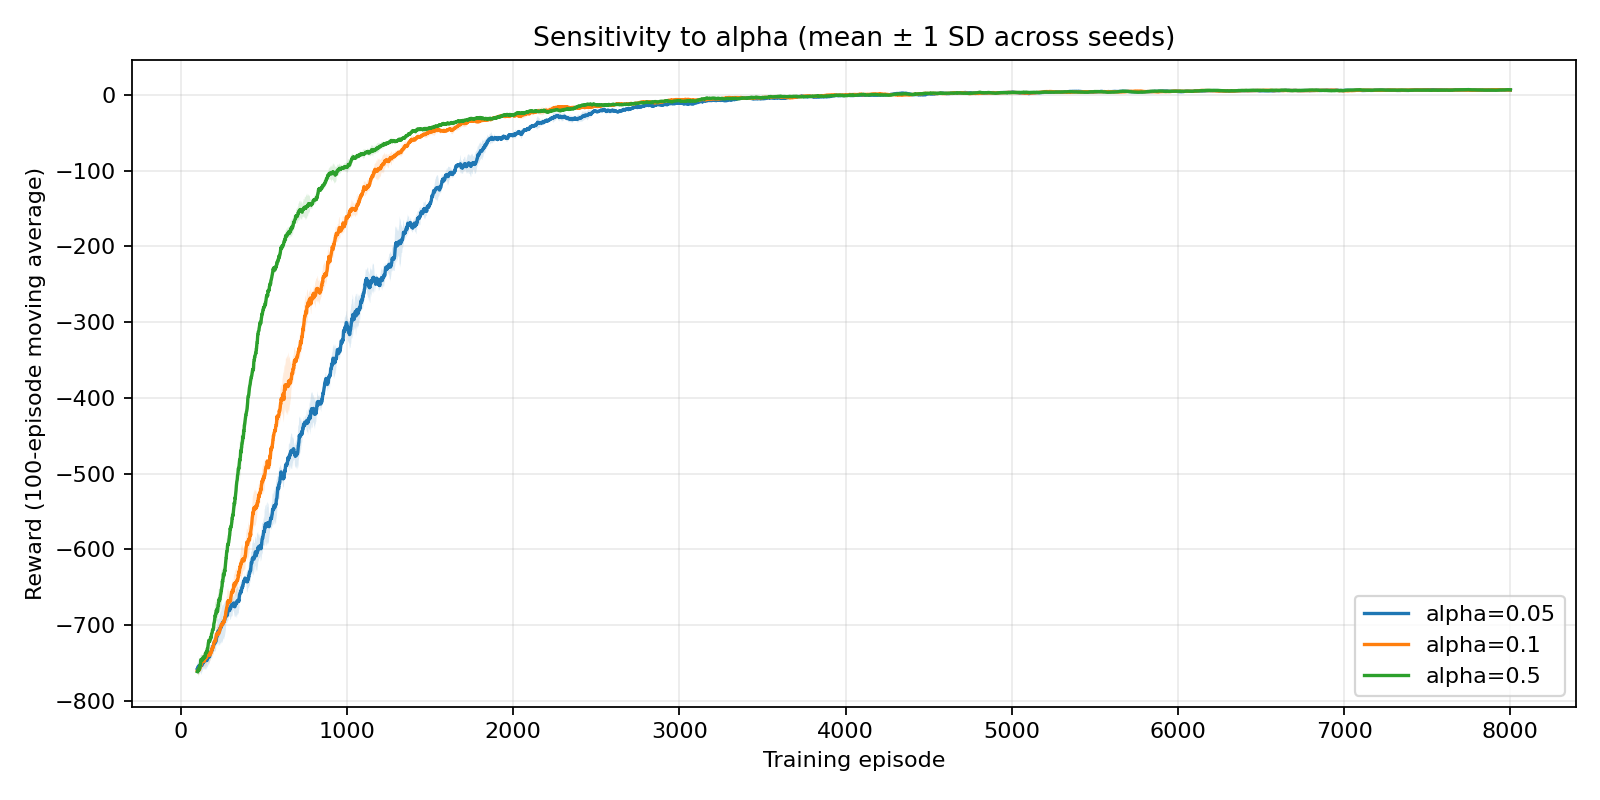

Comparison: gamma


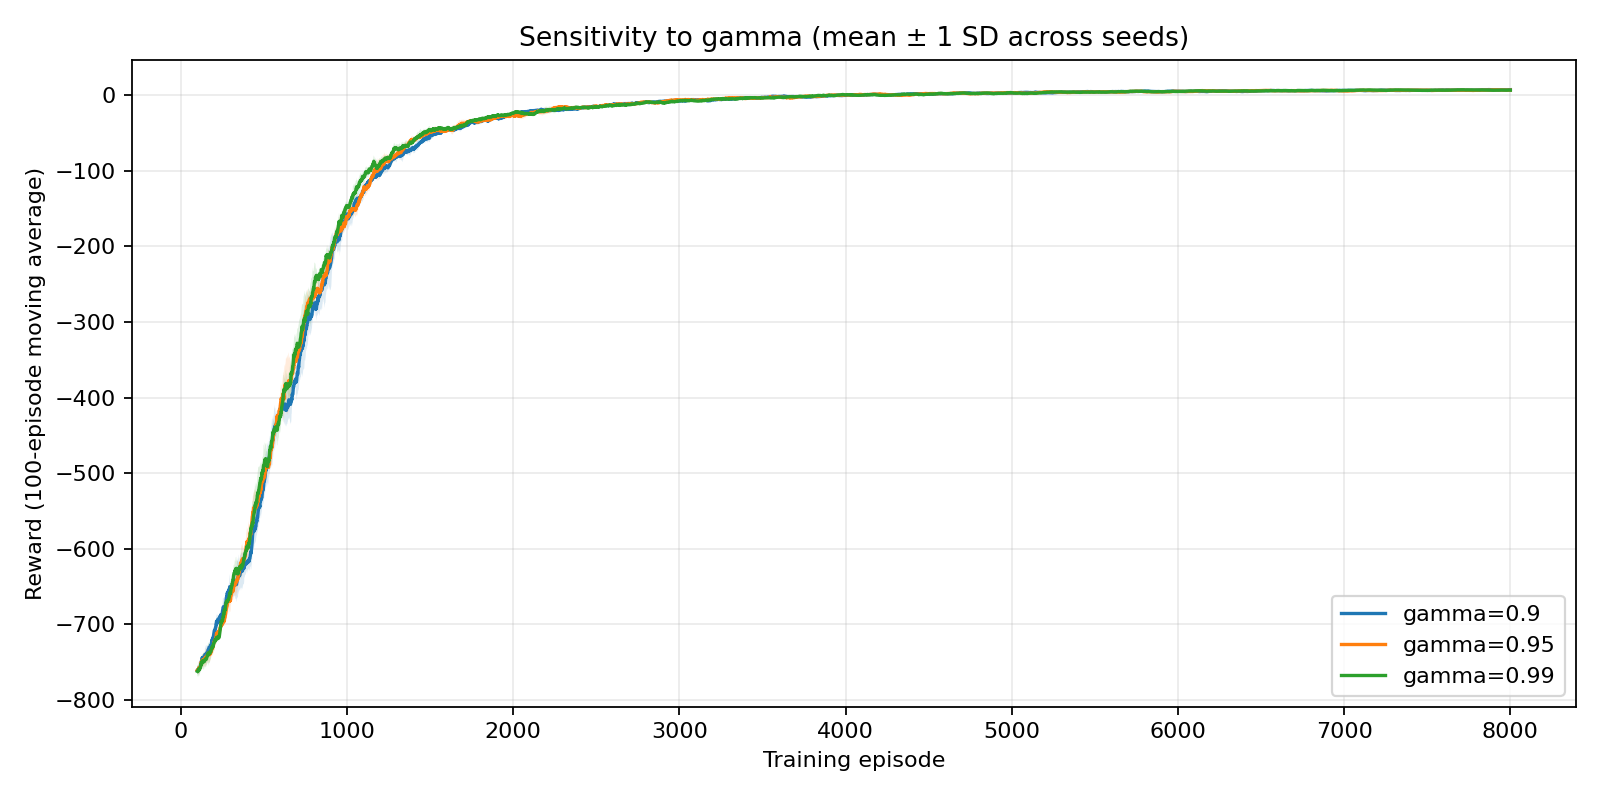

Comparison: epsilon_decay


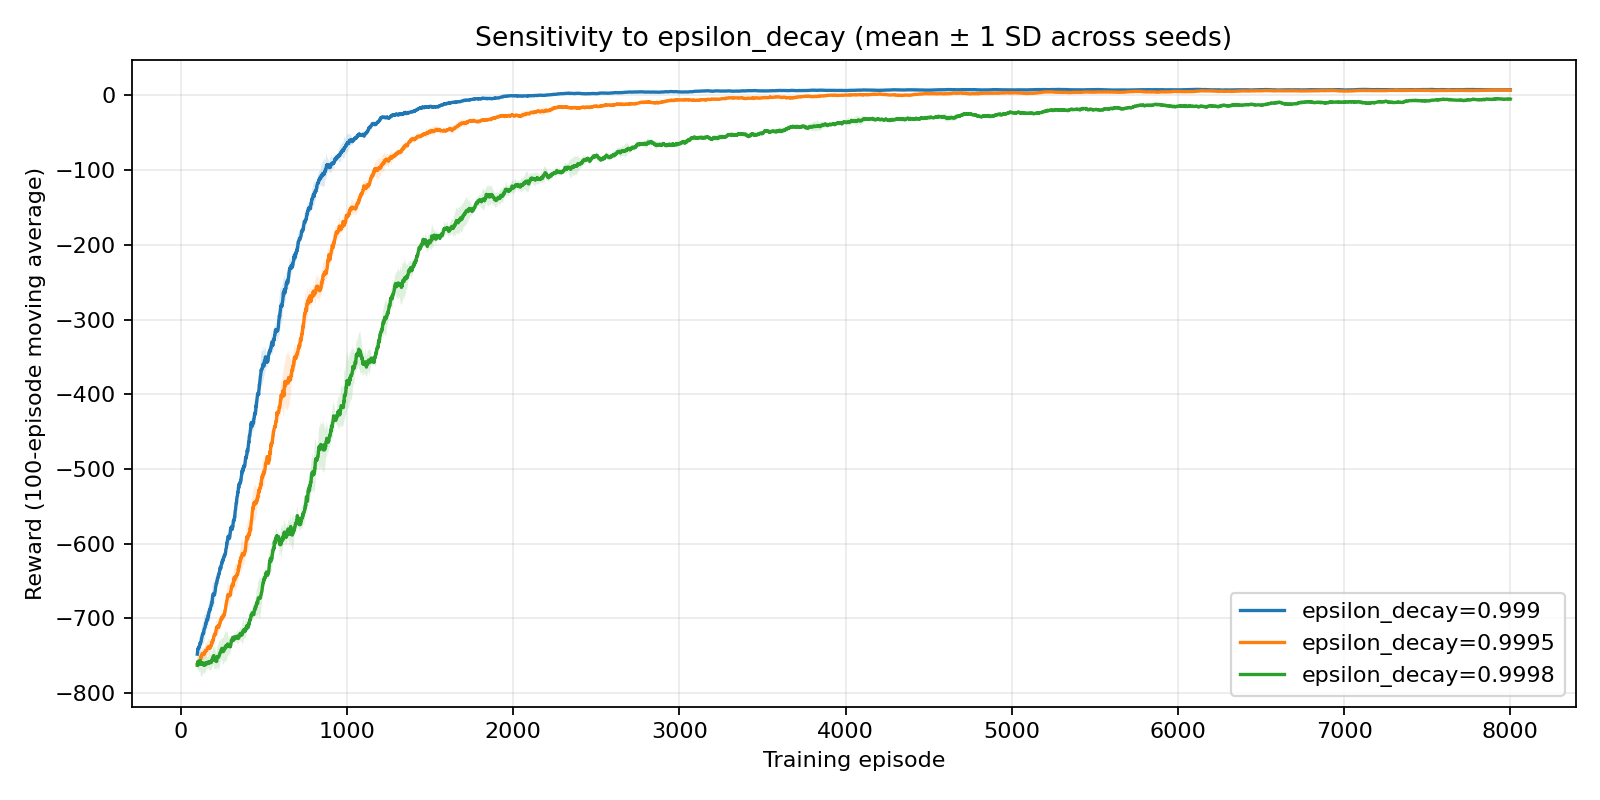

Summary CSV: outputs\notebook\experiments\experiments_summary.csv
parameter,value,seeds,train_episodes,mean_eval_reward,std_eval_reward,mean_success_rate,std_success_rate,mean_average_steps,std_average_steps
alpha,0.05,3,8000,7.920000000000001,0.1135781669160059,1.0,0.0,13.079999999999998,0.1135781669160061
alpha,0.1,3,8000,7.920000000000001,0.1135781669160059,1.0,0.0,13.079999999999998,0.1135781669160061
alpha,0.5,3,8000,7.920000000000001,0.1135781669160059,1.0,0.0,13.079999999999998,0.1135781669160061
gamma,0.9,3,8000,7.920000000000001,0.1135781669160059,1.0,0.0,13.079999999999998,0.1135781669160061
gamma,0.95,3,8000,7.920000000000001,0.1135781669160059,1.0,0.0,13.079999999999998,0.1135781669160061
gamma,0.99,3,8000,7.920000000000001,0.1135781669160059,1.0,0.0,13.079999999999998,0.1135781669160061
epsilon_decay,0.999,3,8000,7.920000000000001,0.1135781669160059,1.0,0.0,13.079999999999998,0.1135781669160061
epsilon_decay,0.9995,3,8000,7.920000000000001,0.1135781669160059,1.0,0.0,13.079

In [17]:
exp_dir = run_experiments(
    episodes=8_000, seeds=(0, 1, 2), eval_episodes=100,
    output_dir=OUTPUT / "experiments", window=100,
)
for name in ("alpha", "gamma", "epsilon_decay"):
    print("Comparison:", name)
    display(Image(filename=str(exp_dir / f"{name}_comparison.png")))
print("Summary CSV:", exp_dir / "experiments_summary.csv")
print((exp_dir / "experiments_summary.csv").read_text(encoding="utf-8"))

## 8. Interpretation (fill in after execution)
- Convergence: [INSERT WHAT YOUR REWARD AND STEPS CURVES ACTUALLY SHOW].
- Chosen learning rate: [INSERT VALUE AND EVIDENCE].
- Chosen discount factor: [INSERT VALUE AND EVIDENCE].
- Chosen exploration decay: [INSERT VALUE AND EVIDENCE].
- Test performance: [INSERT ACTUAL MEAN REWARD, SUCCESS RATE AND STEPS].

**Submission reminder:** Save the notebook after all cells finish so GitHub contains executed outputs, and add the trained Q-table and GIF.